## Cheung Method


2026/3/17

Extracted SBH by Cheung Methods

Inspired by qwen3.5


1. 物理背景與公式根據熱電子發射理論（Thermionic Emission Theory），流經肖特基接面的電流 $I$
   根據熱電子發射理論，電流公式為：$$I = AA^*T^2 \exp\left( \frac{-q\Phi_b}{kT} \right) \exp\left( \frac{q(V - IR_s)}{nkT} \right)$$當我們對兩邊取對數並整理 $V$ 時，會得到：$$V = IR_s + n\Phi_b + \frac{nkT}{q} \ln\left( \frac{I}{AA^*T^2} \right)$$這時候定義 $H(I)$：$$H(I) \equiv V - \left( \frac{nkT}{q} \right) \ln\left( \frac{I}{AA^*T^2} \right)$$將上面的 $V$ 代入，公式會簡化為：$$H(I) = n\Phi_b + IR_s$$

   其中 $I_s$ 為飽和電流，$R_s$ 是中性區與接觸產生的串聯電阻。當 $V > 3kT/q$ 時，Cheung 提出了兩個函數來線性化處理數據。
---

### Method A, B

I. 函數 A：提取 $R_s$ 與 $n$定義函數 $H(I)$ 如下：$$H(I) = V - \left( \frac{nkT}{q} \right) \ln\left( \frac{I}{AA^*T^2} \right)$$經過推導，可得線性關係式：$$H(I) = n\Phi_b + IR_s$$

II. 函數 B：輔助驗證定義另一個函數 $dV/d(\ln I)$：$$\frac{dV}{d(\ln I)} = \frac{nkT}{q} + IR_s$$

1. 第一步：繪製 $\frac{dV}{d(\ln I)}$ vs. $I$ 圖斜率 (Slope): 代表串聯電阻 $R_s$。截距 (Intercept): 代表 $\frac{nkT}{q}$，由此可計算出理想因子 $n$。這一步不依賴能障高度，因此非常穩定。
2. 第二步：繪製 $H(I)$ vs. $I$ 圖利用第一步得到的 $n$，計算出每個電流點對應的 $H(I)$。斜率 (Slope): 同樣代表 $R_s$（可用來與第一步比對，增加準確性）。截距 (Intercept): 代表 $n\Phi_b$，由此計算出能障高度 $\Phi_b$。

### Parameter Loading

Other approches
```python

# ── 方式 2: 只覆蓋面積（最常見） ──
area_cm2 = ConfigLoader.get_area('cafm_tip_10nm')
analyzer = SchottkyAnalyzer(area_cm2=area_cm2)
analyzer.print_config_summary()

# ── 方式 3: 手動指定所有參數（不從 YAML 載入） ──
analyzer = SchottkyAnalyzer(
    area_cm2=7.854e-13,
    temperature=300.0,
    a_star=54.0,
    load_from_yaml=False
)

# ── 方式 4: 混合（面積從 YAML，其他手動） ──
analyzer = SchottkyAnalyzer(
    area_cm2=ConfigLoader.get_area('cafm_tip_10nm'),
    temperature=350,  # 覆蓋 YAML
    a_star=60,        # 覆蓋 YAML
)
```

## Modules Loading

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_scalebar.scalebar import ScaleBar

from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# ✅ 確認 editable install 生效
try:
    from ivs_tools import __version__, HDF5Analyzer
    from ivs_tools.physics.sliding_window_fitter import (
        SlidingWindowCheungFitter, 
        FittingConfig, 
        FittingResult
    )
    from ivs_tools.config_loader import ConfigLoader
    print(f"✅ ivs_tools v{__version__} imported successfully")
except ImportError as e:
    print(f"❌ Import error: {e}")
    print("💡 請執行：pip install -e . 並 restart kernel")
    sys.exit(1)

# 設置 matplotlib 使用 Arial 字體
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,
    'axes.labelsize': 18,
    'axes.titlesize': 18,
    'axes.titleweight': 'bold',
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'figure.titlesize': 20,
    'figure.titleweight': 'bold'
})

print("✅ 所有模組載入成功")


# 測試 1: 載入完整配置
config = ConfigLoader.load()
print("📋 YAML 完整結構:")
for key in config.keys():
    print(f"   {key}: {type(config[key]).__name__}")

# 測試 2: 獲取物理參數
physics = ConfigLoader.get_physics_params()
print(f"\n🔬 物理參數:")
for k, v in physics.items():
    print(f"   {k}: {v}")

# 測試 3: 獲取面積
area = ConfigLoader.get_area('cafm_tip_10nm')
print(f"\n📐 Area (cafm_tip_10nm): {area:.3e} cm²")

# 測試 4: 獲取擬合參數
fit_cfg = ConfigLoader.get_fitting_config('monolayer')
print(f"\n⚙️ 擬合參數 (monolayer):")
for k, v in fit_cfg.items():
    print(f"   {k}: {v}")

# 測試 5: 初始化 Analyzer
#analyzer = SchottkyAnalyzer()
#print(f"\n✅ Analyzer 從 YAML 載入:")
#analyzer.print_config_summary()

✅ ivs_tools v0.1.0 imported successfully
✅ 所有模組載入成功
📋 YAML 完整結構:
   experiment: dict
   physics: dict
   contact_areas: dict
   defaults: dict
   fitting: dict
   batch: dict

🔬 物理參數:
   temperature: 300.0
   a_star: 54.0
   material: MoS2

📐 Area (cafm_tip_10nm): 7.854e-13 cm²

⚙️ 擬合參數 (monolayer):
   window_size: 30
   step_size: 3
   min_r_squared: 0.99
   n_min: 0.5
   n_max: 2.0
   Rs_min: 0.0
   Rs_max: 10000000000.0
   savgol_window: 31
   savgol_polyorder: 3
   current_threshold: 5e-13



## Data Loading


In [2]:
# 數據路徑
root_path = '/home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2'
filename = "2 um 100 pix bias spec map2.h5"
h5map_path = Path(root_path) / filename

# 檢查檔案
if not h5map_path.exists():
    raise FileNotFoundError(f"❌ 找不到檔案: {h5map_path}")

# 初始化 HDF5Analyzer
h5map = HDF5Analyzer(str(h5map_path))
print(f"📁 已載入: {h5map.filepath}")
#print(f"📐 空間: {h5map.metadata.x_pixels} × {h5map.metadata.y_pixels} pixels")
#print(f"⚡ 偏壓: {len(h5map.bias_vector)} 點, [{h5map.bias_vector.min():.2f}, {h5map.bias_vector.max():.2f}] V")

# 查看結構
h5map.list_structure()

# 取得摘要
print("\nSummary:")
summary = h5map.summary()

h5map.print_usage()

📁 已載入: /home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2/2 um 100 pix bias spec map2.h5
DATASET: bias (Shape: (500,), Dtype: float64)
DATASET: current_fwd (Shape: (500, 10000), Dtype: float64)

METADATA:
  Experiment: Bias-Spectroscopy-Current-Map-fwd
  Bias Points: 500
  Pixels: 100 x 100
  Range: 2.00e-06 x 2.00e-06 m

Summary:
📋 數據摘要
----------------------------------------
文件: 2 um 100 pix bias spec map2.h5
路徑: /home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2/2 um 100 pix bias spec map2.h5

📐 空間維度:
  X方向像素: 100
  Y方向像素: 100

⚡ 偏壓維度:
  偏壓點數: 500
  偏壓範圍: -2.000 到 2.000 V

💾 數據陣列:
  Current Map: (500, 10000) (float64)
    總大小: 38.15 MB
    範圍: -4.328e-05 到 3.409e-05 A
  Bias Vector: (500,) (float64)
----------------------------------------
HDF5Analyzer 使用指南

📁 數據屬性:
----------------------------------------
  • filepath: 未加載或不可用
  • metadata: 未加載或不可用
  • current_map: 未加載或不可用
  • bias_vector: 未加載或不可用

⚙️ 主要方法:
------------------

In [3]:
# %%
x, y = 75, 71
spec = h5map.get_spectrum_at_pixel(x, y)[3:]  # skip noise
bias = h5map.bias_vector[3:]


area_cm2 = ConfigLoader.get_area('cafm_tip_10nm')
print(f"📐 CAFM tip (10 nm): Area = {area_cm2:.3e} cm²")

# 其他物理參數（可從 YAML 或手動設定）
T = 300.0        # K
a_star = 54.0    # A/cm²/K², MoS₂

print(f"\n🔬 物理參數:")
print(f"   Temperature: {T} K")
print(f"   A**: {a_star} A/cm²/K²")


📐 CAFM tip (10 nm): Area = 7.854e-13 cm²

🔬 物理參數:
   Temperature: 300.0 K
   A**: 54.0 A/cm²/K²


In [4]:

# 建立擬合器（使用預設配置）
fitter = SlidingWindowCheungFitter()

print("📐 FittingConfig 預設參數:")
print(f"   window_size: {fitter.config.window_size}")
print(f"   min_r_squared: {fitter.config.min_r_squared}")
print(f"   n_range: [{fitter.config.n_min}, {fitter.config.n_max}]")
print(f"   current_threshold: {fitter.config.current_threshold:.2e} A")

# 執行擬合
print(f"\n🔍 執行擬合 (layer_type='monolayer')...")
result = fitter.fit(
    bias=bias,
    current=spec,
    area_cm2=area_cm2,
    T=T,
    a_star=a_star,
    layer_type="monolayer"
)

# 顯示結果
print("\n" + "="*60)
if result.success:
    print("✅ 擬合成功!")
    print(f"   ΦB (SBH)     = {result.phi_b:.3f} eV")
    print(f"   n (ideality) = {result.n:.2f}")
    print(f"   Rs           = {result.Rs:.2e} Ω")
    print(f"   R²           = {result.r_squared:.4f}")
    print(f"   Score        = {result.score:.3f}")
    print(f"   擬合區間     = {result.fit_range[0]:.2f} ~ {result.fit_range[1]:.2f} V")
else:
    print("❌ 擬合失敗!")
    print(f"   警告：{result.warning}")
    
    # 顯示診斷統計
    if result.diagnostic:
        print(f"\n📊 診斷統計:")
        for k, v in result.diagnostic.items():
            if isinstance(v, dict):
                print(f"   {k}:")
                for k2, v2 in v.items():
                    print(f"      {k2}: {v2}")
            elif isinstance(v, list) and len(v) > 0:
                print(f"   {k}: [{len(v)} items]")
            else:
                print(f"   {k}: {v}")
                

📐 FittingConfig 預設參數:
   window_size: 25
   min_r_squared: 0.9
   n_range: [0.5, 5.0]
   current_threshold: 5.00e-13 A

🔍 執行擬合 (layer_type='monolayer')...

✅ 擬合成功!
   ΦB (SBH)     = 0.151 eV
   n (ideality) = 1.41
   Rs           = 5.37e+05 Ω
   R²           = 0.9461
   Score        = 0.772
   擬合區間     = 0.00 ~ 0.20 V


📐 擬合參數:
   window_size: 30, step: 5
   min_r_squared: 0.99, n_range: [1.0, 2.0]
   current_threshold: 1.00e-12 A
   V_T: 0.0259 V

🔍 Step 1: 預處理...
   原始點數：497
   有效點數 (>threshold): 238
   電流範圍：5.47e-09 ~ 4.29e-05 A
   ✅ 有效點數足夠
   平滑後點數：238

🔍 Step 2: 計算 Cheung Function I...
   ln(I) 範圍：-16.63 ~ -10.29
   dV/d(lnI) 範圍：-1043458.8610 ~ 332759.9755 V

🔍 Step 3: 滑動窗口掃描...
   constant_term (A*A**T²): 3.817e-06
   bias idx, 0:30 | value: 0.10020041:0.33266544
   bias idx, 5:35 | value: 0.14028049:0.37274551
   bias idx, 10:40 | value: 0.18036079:0.41282558
   bias idx, 15:45 | value: 0.22044086:0.45290589
   bias idx, 20:50 | value: 0.26052117:0.49298596
   bias idx, 25:55 | value: 0.30060124:0.53306627
   bias idx, 30:60 | value: 0.34068131:0.57314634
   bias idx, 35:65 | value: 0.38076162:0.61322641
   bias idx, 40:70 | value: 0.42084169:0.65330672
   bias idx, 45:75 | value: 0.46092176:0.69338679
   bias idx, 50:80 | value: 0.50100207:0.73346686
   bias idx, 55:85 | value: 0.54108214:0.77

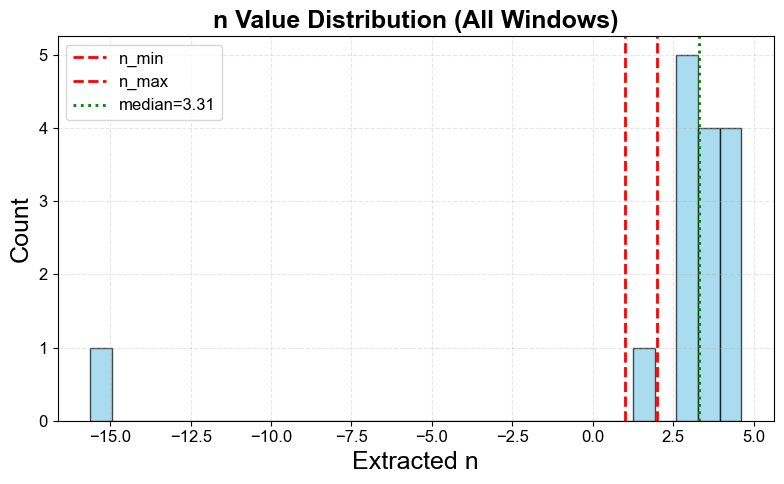


📈 R²分佈:
   最佳：0.9970
   平均：0.6691
   閾值：0.99

❌ 擬合失敗!
   原因：多階段篩選失敗


In [5]:
# %% [markdown]
# ## Step 5b: 即時診斷 - 手動執行擬合邏輯
# 目的：找出為什麼 diagnostic 是空的

from scipy import stats
from scipy.signal import savgol_filter

# ── 參數設定 ──
area_cm2 = ConfigLoader.get_area('cafm_tip_10nm')
T = 300.0
a_star = 54.0
q = 1.6021766e-19
k_B_J = 1.380649e-23
V_T = (k_B_J * T) / q

# 擬合參數（monolayer）
window_size = 30
step_size = 5
min_r_squared = 0.99
n_min, n_max = 1.0, 2.0
current_threshold = 1e-12
savgol_window = 21

print(f"📐 擬合參數:")
print(f"   window_size: {window_size}, step: {step_size}")
print(f"   min_r_squared: {min_r_squared}, n_range: [{n_min}, {n_max}]")
print(f"   current_threshold: {current_threshold:.2e} A")
print(f"   V_T: {V_T:.4f} V")

# ── 步驟 1: 預處理 ──
print("\n🔍 Step 1: 預處理...")
I_abs = np.abs(spec)
mask_valid = (I_abs > current_threshold) & (bias > 0.1)

print(f"   原始點數：{len(I_abs)}")
print(f"   有效點數 (>threshold): {np.sum(mask_valid)}")
print(f"   電流範圍：{np.min(I_abs):.2e} ~ {np.max(I_abs):.2e} A")

if np.sum(mask_valid) < window_size:
    print(f"   ❌ 有效點數 {np.sum(mask_valid)} < window_size {window_size}")
    print(f"   💡 建議：降低 current_threshold 或檢查數據品質")
else:
    print(f"   ✅ 有效點數足夠")

bias_proc = bias[mask_valid]
I_proc = I_abs[mask_valid]

# Savitzky-Golay 平滑
window = min(savgol_window, len(I_proc) - 2)
if window % 2 == 0: window += 1
I_smooth = savgol_filter(I_proc, window_length=window, polyorder=3)
print(f"   平滑後點數：{len(I_smooth)}")

# ── 步驟 2: 計算 Cheung Function I ──
print("\n🔍 Step 2: 計算 Cheung Function I...")
ln_I = np.log(I_smooth + 1e-20)
dV_dlnI = np.gradient(bias_proc, ln_I)
print(f"   ln(I) 範圍：{np.min(ln_I):.2f} ~ {np.max(ln_I):.2f}")
print(f"   dV/d(lnI) 範圍：{np.min(dV_dlnI):.4f} ~ {np.max(dV_dlnI):.4f} V")

# ── 步驟 3: 滑動窗口掃描 ──
print("\n🔍 Step 3: 滑動窗口掃描...")
constant_term = area_cm2 * a_star * (T**2)
print(f"   constant_term (A*A**T²): {constant_term:.3e}")

stats_counter = {
    'total': 0, 'monotonic_fail': 0, 'r2_pre_fail': 0, 
    'constraint_fail': 0, 'r2_final_fail': 0, 'rs_mismatch': 0, 'success': 0
}
n_samples = []
r2_samples = []
best_score = 0
best_result = None

for start_idx in range(0, len(bias_proc) - window_size + 1, step_size):
    end_idx = start_idx + window_size
    stats_counter['total'] += 1

    I_win = I_smooth[start_idx:end_idx]
    V_win = bias_proc[start_idx:end_idx]
    y_win = dV_dlnI[start_idx:end_idx]
    
    print(f"   bias idx, {start_idx}:{end_idx} | value: {V_win[0]}:{V_win[-1]}")

    # 檢查 1: 單調性
    if not np.all(np.diff(I_win) > 0):
        stats_counter['monotonic_fail'] += 1
        continue
    
    # 檢查 2: Cheung I 線性擬合
    slope_a, intercept_a, r_value, _, _ = stats.linregress(I_win, y_win)
    r2_a = r_value**2
    n_ext = intercept_a / V_T
    Rs_ext = slope_a
    
    n_samples.append(n_ext)
    r2_samples.append(r2_a)
    
    if r2_a < 0.9:
        stats_counter['r2_pre_fail'] += 1
        continue
    
    # 檢查 3: 物理約束
    if not (n_min < n_ext < n_max):
        stats_counter['constraint_fail'] += 1
        continue
    if r2_a < min_r_squared:
        stats_counter['constraint_fail'] += 1
        continue
    
    # 檢查 4: Cheung II
    H_I = V_win - (n_ext * V_T * np.log(I_win / constant_term))
    slope_b, intercept_b, r_value_b, _, _ = stats.linregress(I_win, H_I)
    r2_b = r_value_b**2
    
    if r2_b < min_r_squared * 0.95:
        stats_counter['r2_final_fail'] += 1
        continue
    
    phi_b = intercept_b / n_ext
    Rs_b = slope_b
    
    # 檢查 5: Rs 一致性
    if Rs_ext > 1e-10 and abs(Rs_ext - Rs_b) / Rs_ext > 0.3:
        stats_counter['rs_mismatch'] += 1
        continue
    
    # ✅ 所有檢查通過
    stats_counter['success'] += 1
    score = r2_a * 0.6 + np.log10(I_win[-1]/(I_win[0]+1e-20))/2 * 0.3 + 0.1
    
    if score > best_score:
        best_score = score
        best_result = {
            'n': n_ext, 'Rs': Rs_ext, 'phi_b': phi_b, 'r2': r2_a,
            'V_range': (V_win[0], V_win[-1]),
            'indices': (start_idx, end_idx)
        }

# ── 步驟 4: 顯示統計 ──
print("\n" + "="*60)
print("📊 掃描統計:")
print(f"   總窗口數：{stats_counter['total']}")
print(f"   單調失敗：{stats_counter['monotonic_fail']} ({stats_counter['monotonic_fail']/max(stats_counter['total'],1)*100:.1f}%)")
print(f"   R²預篩失敗：{stats_counter['r2_pre_fail']} ({stats_counter['r2_pre_fail']/max(stats_counter['total'],1)*100:.1f}%)")
print(f"   約束失敗：{stats_counter['constraint_fail']} ({stats_counter['constraint_fail']/max(stats_counter['total'],1)*100:.1f}%)")
print(f"   R²最終失敗：{stats_counter['r2_final_fail']} ({stats_counter['r2_final_fail']/max(stats_counter['total'],1)*100:.1f}%)")
print(f"   Rs 不一致：{stats_counter['rs_mismatch']} ({stats_counter['rs_mismatch']/max(stats_counter['total'],1)*100:.1f}%)")
print(f"   ✅ 通過所有檢查：{stats_counter['success']}")

if n_samples:
    print(f"\n📈 n 值分佈:")
    print(f"   範圍：[{min(n_samples):.2f}, {max(n_samples):.2f}]")
    print(f"   平均：{np.mean(n_samples):.2f} ± {np.std(n_samples):.2f}")
    print(f"   約束：[{n_min}, {n_max}]")
    print(f"   中位數：{np.median(n_samples):.2f}")
    
    # 顯示 n 值直方圖
    fig, ax = plt.subplots(1, 1, figsize=(8, 5))
    ax.hist(n_samples, bins=30, edgecolor='black', alpha=0.7, color='skyblue')
    ax.axvline(x=n_min, color='red', ls='--', lw=2, label='n_min')
    ax.axvline(x=n_max, color='red', ls='--', lw=2, label='n_max')
    ax.axvline(x=np.median(n_samples), color='green', ls=':', lw=2, label=f'median={np.median(n_samples):.2f}')
    ax.set_xlabel('Extracted n')
    ax.set_ylabel('Count')
    ax.set_title('n Value Distribution (All Windows)')
    ax.legend()
    ax.grid(True, ls='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

if r2_samples:
    print(f"\n📈 R²分佈:")
    print(f"   最佳：{max(r2_samples):.4f}")
    print(f"   平均：{np.mean(r2_samples):.4f}")
    print(f"   閾值：{min_r_squared}")

# ── 步驟 5: 最終結果 ──
print("\n" + "="*60)
if best_result:
    print("✅ 擬合成功!")
    print(f"   ΦB = {best_result['phi_b']:.3f} eV")
    print(f"   n = {best_result['n']:.2f}")
    print(f"   Rs = {best_result['Rs']:.2e} Ω")
    print(f"   R² = {best_result['r2']:.4f}")
    print(f"   V_range = {best_result['V_range'][0]:.2f} ~ {best_result['V_range'][1]:.2f} V")
else:
    print("❌ 擬合失敗!")
    # 分析主要原因
    if stats_counter['total'] == 0:
        print(f"   原因：無可掃描窗口 (數據點 {len(bias_proc)} < window {window_size})")
    elif stats_counter['monotonic_fail'] == stats_counter['total']:
        print(f"   原因：所有窗口電流非單調 → 數據噪聲大或包含反向偏壓")
    elif stats_counter['r2_pre_fail'] == stats_counter['total']:
        print(f"   原因：所有窗口 R² < 0.9 → 線性關係差，可能非熱電子發射主導")
    elif stats_counter['constraint_fail'] == stats_counter['total']:
        print(f"   原因：所有窗口 n 或 R² 超出約束")
        print(f"   💡 建議：放寬 n_range 到 [{min(n_samples):.1f}, {max(n_samples):.1f}]")
    elif stats_counter['success'] > 0:
        print(f"   原因：找到 {stats_counter['success']} 個有效窗口但 score 太低")
    else:
        print(f"   原因：多階段篩選失敗")

In [ ]:
# ## Step 5d: 放寬約束測試

🔧 放寬後的參數:
   window_size: 25 (原 30)
   min_r_squared: 0.9 (原 0.99)
   n_range: [0.5, 5.0] (原 [1.0, 2.0])
   savgol_window: 31 (原 21)

📊 掃描統計 (放寬後):
   總窗口：72
   單調失敗：45
   R²預篩：12
   約束失敗：3
   R²最終：0
   Rs 不一致：0
   ✅ 通過：12

📈 n 值分佈 (放寬後):
   範圍：[-108.24, 4.86]
   平均：-1.84 ± 21.43
   中位數：3.25

✅ 放寬後擬合成功!
   ΦB = 0.161 eV
   n = 3.02
   Rs = 6.22e+03 Ω
   R² = 0.9902
   V_range = 0.44 ~ 0.63 V


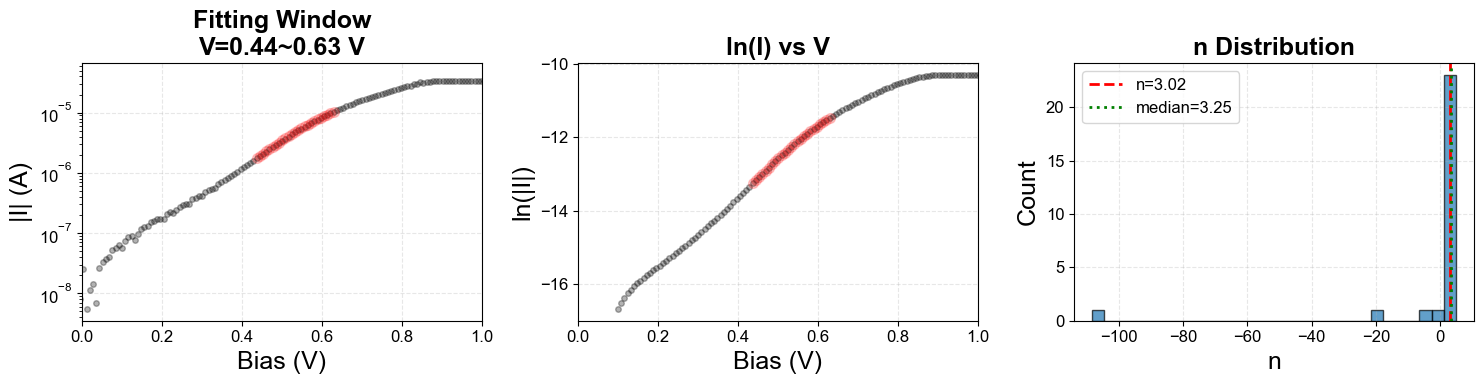


💡 物理意義討論:
   ⚠️ n = 3.02 > 2，可能原因：
      • 界面態密度高（interface states）
      • 串聯電阻效應（series resistance）
      • Tunneling 貢獻（thermionic-field emission）
      • 非理想接觸（non-ideal Schottky contact）

   📝 建議：
      • 報告時說明 n 值偏高，可能非純熱電子發射
      • 考慮用 activation energy method 驗證 ΦB
      • 檢查其他像素是否有類似趨勢


In [6]:
# 根據 n 分佈調整參數

from scipy import stats
from scipy.signal import savgol_filter

# ── 調整後的參數 ──
area_cm2 = ConfigLoader.get_area('cafm_tip_10nm')
T = 300.0
a_star = 54.0
q = 1.6021766e-19
k_B_J = 1.380649e-23
V_T = (k_B_J * T) / q

#  關鍵調整：
window_size = 25           # 減小窗口（避免極端值影響）
step_size = 3              # 更細步長
min_r_squared = 0.90       # 放寬 R²（從 0.99 → 0.90）
n_min, n_max = 0.5, 5.0    # 放寬 n（從 [1,2] → [0.5, 5]）
current_threshold = 5e-13  # 降低閾值
savgol_window = 31         # 增加平滑窗口（減少噪聲）

print(f"🔧 放寬後的參數:")
print(f"   window_size: {window_size} (原 30)")
print(f"   min_r_squared: {min_r_squared} (原 0.99)")
print(f"   n_range: [{n_min}, {n_max}] (原 [1.0, 2.0])")
print(f"   savgol_window: {savgol_window} (原 21)")

# ── 預處理 ──
I_abs = np.abs(spec)
mask_valid = (I_abs > current_threshold) & (bias > 0.1)
bias_proc = bias[mask_valid]
I_proc = I_abs[mask_valid]

# 更強的平滑
window = min(savgol_window, len(I_proc) - 2)
if window % 2 == 0: window += 1
I_smooth = savgol_filter(I_proc, window_length=window, polyorder=3)

# Cheung Function I
ln_I = np.log(I_smooth + 1e-20)
dV_dlnI = np.gradient(bias_proc, ln_I)

# ── 掃描 ──
constant_term = area_cm2 * a_star * (T**2)
stats_counter = {
    'total': 0, 'monotonic_fail': 0, 'r2_pre_fail': 0, 
    'constraint_fail': 0, 'r2_final_fail': 0, 'rs_mismatch': 0, 'success': 0
}
n_samples_new = []
best_score = 0
best_result = None
valid_windows = []

for start_idx in range(0, len(bias_proc) - window_size + 1, step_size):
    end_idx = start_idx + window_size
    stats_counter['total'] += 1
    
    I_win = I_smooth[start_idx:end_idx]
    V_win = bias_proc[start_idx:end_idx]
    y_win = dV_dlnI[start_idx:end_idx]
    
    # 單調性
    if not np.all(np.diff(I_win) > 0):
        stats_counter['monotonic_fail'] += 1
        continue
    
    # Cheung I
    slope_a, intercept_a, r_value, _, _ = stats.linregress(I_win, y_win)
    r2_a = r_value**2
    n_ext = intercept_a / V_T
    Rs_ext = slope_a
    
    n_samples_new.append(n_ext)
    
    if r2_a < 0.8:  # 預篩更寬
        stats_counter['r2_pre_fail'] += 1
        continue
    
    # 約束檢查
    if not (n_min < n_ext < n_max):
        stats_counter['constraint_fail'] += 1
        continue
    if r2_a < min_r_squared:
        stats_counter['constraint_fail'] += 1
        continue
    
    # Cheung II
    H_I = V_win - (n_ext * V_T * np.log(I_win / constant_term))
    slope_b, intercept_b, r_value_b, _, _ = stats.linregress(I_win, H_I)
    r2_b = r_value_b**2
    
    if r2_b < min_r_squared * 0.95:
        stats_counter['r2_final_fail'] += 1
        continue
    
    phi_b = intercept_b / n_ext
    Rs_b = slope_b
    
    # Rs 一致性
    if Rs_ext > 1e-10 and abs(Rs_ext - Rs_b) / Rs_ext > 0.3:
        stats_counter['rs_mismatch'] += 1
        continue
    
    # ✅ 通過
    stats_counter['success'] += 1
    score = r2_a * 0.6 + np.log10(I_win[-1]/(I_win[0]+1e-20))/2 * 0.3 + 0.1
    
    valid_windows.append({
        'n': n_ext, 'phi_b': phi_b, 'r2': r2_a, 
        'V_range': (V_win[0], V_win[-1]),
        'indices': (start_idx, end_idx)
    })
    
    if score > best_score:
        best_score = score
        best_result = {
            'n': n_ext, 'Rs': Rs_ext, 'phi_b': phi_b, 'r2': r2_a,
            'V_range': (V_win[0], V_win[-1]),
            'indices': (start_idx, end_idx)
        }

# ── 結果 ──
print("\n" + "="*60)
print("📊 掃描統計 (放寬後):")
print(f"   總窗口：{stats_counter['total']}")
print(f"   單調失敗：{stats_counter['monotonic_fail']}")
print(f"   R²預篩：{stats_counter['r2_pre_fail']}")
print(f"   約束失敗：{stats_counter['constraint_fail']}")
print(f"   R²最終：{stats_counter['r2_final_fail']}")
print(f"   Rs 不一致：{stats_counter['rs_mismatch']}")
print(f"   ✅ 通過：{stats_counter['success']}")

if n_samples_new:
    print(f"\n📈 n 值分佈 (放寬後):")
    print(f"   範圍：[{min(n_samples_new):.2f}, {max(n_samples_new):.2f}]")
    print(f"   平均：{np.mean(n_samples_new):.2f} ± {np.std(n_samples_new):.2f}")
    print(f"   中位數：{np.median(n_samples_new):.2f}")

print("\n" + "="*60)
if best_result:
    print("✅ 放寬後擬合成功!")
    print(f"   ΦB = {best_result['phi_b']:.3f} eV")
    print(f"   n = {best_result['n']:.2f}")
    print(f"   Rs = {best_result['Rs']:.2e} Ω")
    print(f"   R² = {best_result['r2']:.4f}")
    print(f"   V_range = {best_result['V_range'][0]:.2f} ~ {best_result['V_range'][1]:.2f} V")
    
    # 視覺化最佳擬合
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    idx_start, idx_end = best_result['indices']
    
    # Panel 1: I-V
    axes[0].semilogy(bias, np.abs(spec), 'ko', ms = 4, alpha=0.3)
    axes[0].semilogy(bias_proc[idx_start:idx_end], 
                    I_smooth[idx_start:idx_end], 'ro', ms = 7, alpha=0.2)
    axes[0].set_xlabel('Bias (V)')
    axes[0].set_ylabel('|I| (A)')
    axes[0].set_xlim(0, 1)
    axes[0].set_title(f'Fitting Window\nV={best_result["V_range"][0]:.2f}~{best_result["V_range"][1]:.2f} V')
    axes[0].grid(True, ls='--', alpha=0.3)
    
    # Panel 2: ln(I)-V
    axes[1].plot(bias_proc, np.log(I_smooth + 1e-20), 'ko', ms=4, alpha=0.3)
    axes[1].plot(bias_proc[idx_start:idx_end], 
                np.log(I_smooth[idx_start:idx_end] + 1e-20), 'ro', ms = 7, alpha=0.2)
    axes[1].set_xlabel('Bias (V)')
    axes[1].set_ylabel('ln(|I|)')
    axes[1].set_xlim(0, 1)
    axes[1].set_title('ln(I) vs V')
    axes[1].grid(True, ls='--', alpha=0.3)
    
    # Panel 3: n 值分佈
    axes[2].hist(n_samples_new, bins=30, edgecolor='black', alpha=0.7)
    axes[2].axvline(x=best_result['n'], color='red', ls='--', lw=2, label=f'n={best_result["n"]:.2f}')
    axes[2].axvline(x=np.median(n_samples_new), color='green', ls=':', lw=2, label=f'median={np.median(n_samples_new):.2f}')
    axes[2].set_xlabel('n')
    axes[2].set_ylabel('Count')
    axes[2].set_title('n Distribution')
    axes[2].legend(fontsize=12)
    axes[2].grid(True, ls='--', alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 物理意義討論
    print("\n💡 物理意義討論:")
    if best_result['n'] > 2.0:
        print(f"   ⚠️ n = {best_result['n']:.2f} > 2，可能原因：")
        print(f"      • 界面態密度高（interface states）")
        print(f"      • 串聯電阻效應（series resistance）")
        print(f"      • Tunneling 貢獻（thermionic-field emission）")
        print(f"      • 非理想接觸（non-ideal Schottky contact）")
    else:
        print(f"   ✅ n = {best_result['n']:.2f} 在合理範圍 (1-2)")
    
    print(f"\n   📝 建議：")
    print(f"      • 報告時說明 n 值偏高，可能非純熱電子發射")
    print(f"      • 考慮用 activation energy method 驗證 ΦB")
    print(f"      • 檢查其他像素是否有類似趨勢")
    
else:
    print("❌ 放寬後仍失敗")
    print(f"   💡 建議：")
    print(f"      • 檢查原始 I-V 曲線品質")
    print(f"      • 這個像素可能不適合 Cheung method")
    print(f"      • 嘗試其他像素或改用其他分析方法")

In [7]:
v_ranges = [item['V_range'] for item in valid_windows]
v_ranges

[(np.float64(0.19639277), np.float64(0.38877749)),
 (np.float64(0.38877749), np.float64(0.58116245)),
 (np.float64(0.41282558), np.float64(0.60521054)),
 (np.float64(0.43687367), np.float64(0.62925863)),
 (np.float64(0.46092176), np.float64(0.65330672)),
 (np.float64(0.48496985), np.float64(0.67735481)),
 (np.float64(0.50901818), np.float64(0.7014029)),
 (np.float64(0.53306627), np.float64(0.72545099)),
 (np.float64(0.55711436), np.float64(0.74949908)),
 (np.float64(0.58116245), np.float64(0.77354717)),
 (np.float64(0.60521054), np.float64(0.79759526)),
 (np.float64(0.62925863), np.float64(0.82164335))]

In [8]:
v_ranges = [item['V_range'] for item in valid_windows]
v_ranges

[(np.float64(0.19639277), np.float64(0.38877749)),
 (np.float64(0.38877749), np.float64(0.58116245)),
 (np.float64(0.41282558), np.float64(0.60521054)),
 (np.float64(0.43687367), np.float64(0.62925863)),
 (np.float64(0.46092176), np.float64(0.65330672)),
 (np.float64(0.48496985), np.float64(0.67735481)),
 (np.float64(0.50901818), np.float64(0.7014029)),
 (np.float64(0.53306627), np.float64(0.72545099)),
 (np.float64(0.55711436), np.float64(0.74949908)),
 (np.float64(0.58116245), np.float64(0.77354717)),
 (np.float64(0.60521054), np.float64(0.79759526)),
 (np.float64(0.62925863), np.float64(0.82164335))]

In [8]:
valid_windows

[{'n': np.float64(3.1555272855034873),
  'phi_b': np.float64(0.15559774135203797),
  'r2': np.float64(0.9594708633864557),
  'V_range': (np.float64(0.40480971), np.float64(0.59719443)),
  'indices': (297, 322)},
 {'n': np.float64(3.043856701008201),
  'phi_b': np.float64(0.16031473454052023),
  'r2': np.float64(0.988204939397256),
  'V_range': (np.float64(0.4288578), np.float64(0.62124252)),
  'indices': (300, 325)},
 {'n': np.float64(2.960844598855486),
  'phi_b': np.float64(0.1642406177982797),
  'r2': np.float64(0.994145516697527),
  'V_range': (np.float64(0.45290589), np.float64(0.64529061)),
  'indices': (303, 328)},
 {'n': np.float64(2.9139291575704083),
  'phi_b': np.float64(0.1666220301331528),
  'r2': np.float64(0.9981648939191999),
  'V_range': (np.float64(0.47695398), np.float64(0.6693387)),
  'indices': (306, 331)},
 {'n': np.float64(2.8918947505586114),
  'phi_b': np.float64(0.1677891425762375),
  'r2': np.float64(0.997725950893412),
  'V_range': (np.float64(0.50100207), n

💾 圖表已儲存至：analysis_results/schottky_plots/pixel_75_71_n3.02_phiB0.161eV_V0.44-0.63V.png
   檔案大小：306.2 KB
💾 PDF 已儲存至：analysis_results/schottky_plots/pixel_75_71_n3.02_phiB0.161eV_V0.44-0.63V.pdf


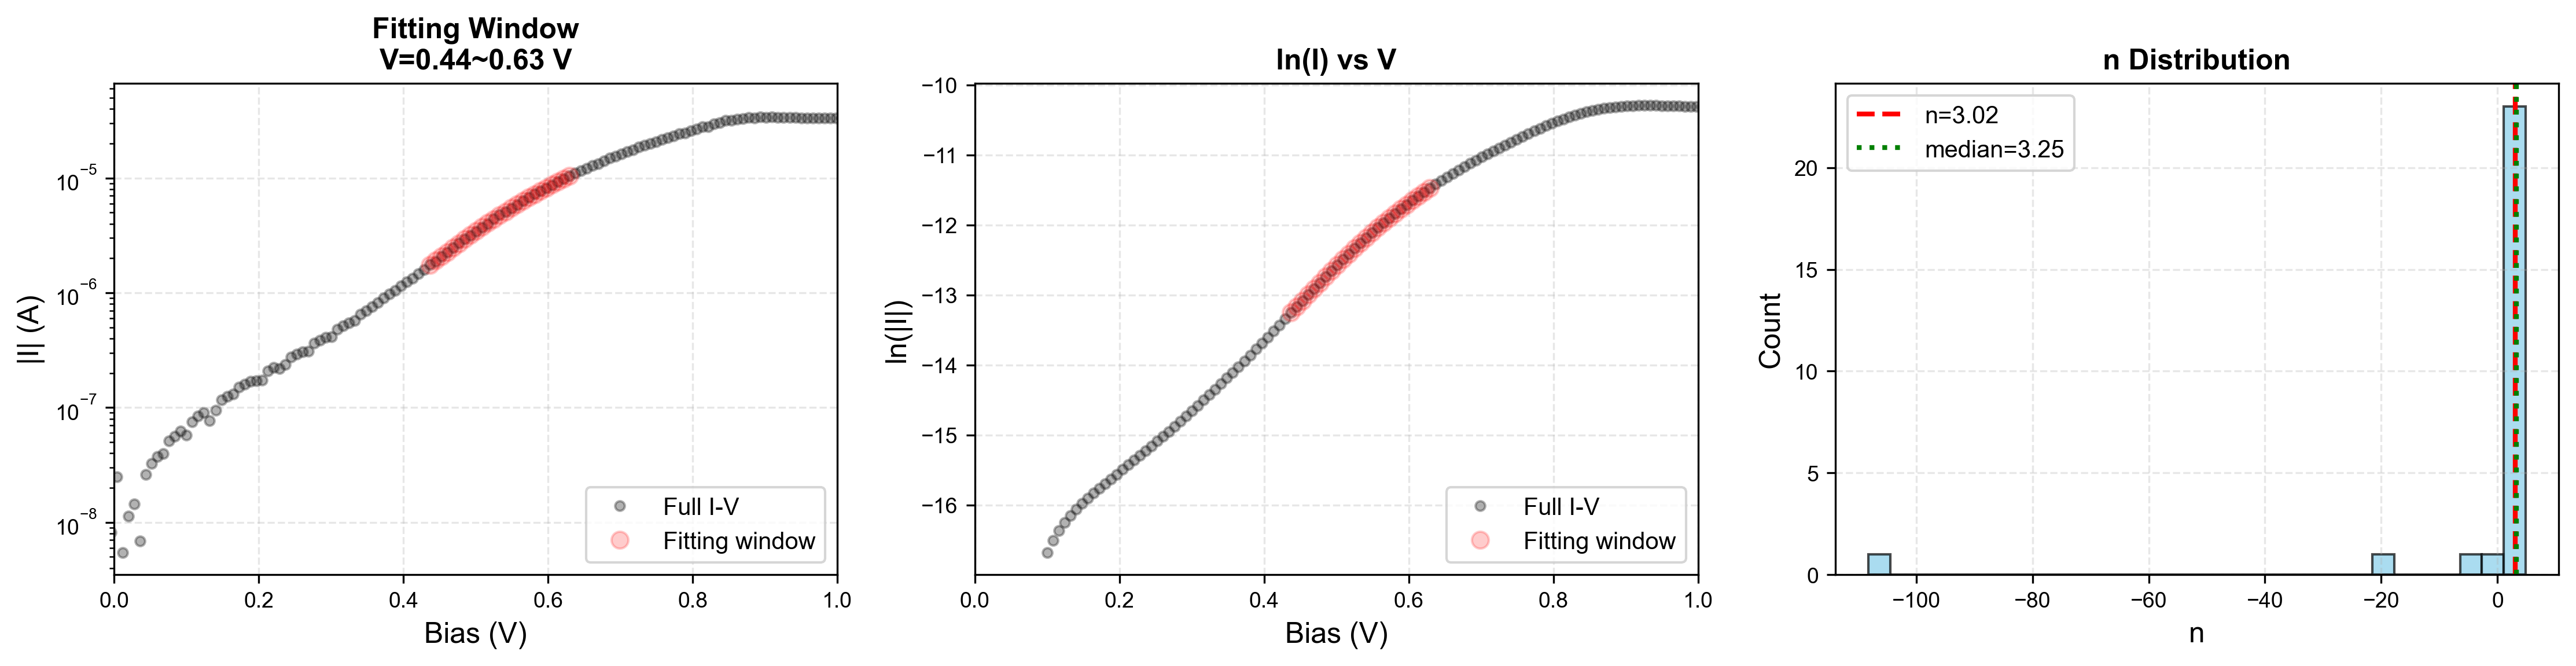

💾 參數已儲存至：analysis_results/schottky_plots/pixel_75_71_n3.02_phiB0.161eV_V0.44-0.63V.json


In [9]:
# 儲存擬合結果圖

from pathlib import Path

# 建立儲存目錄
save_dir = Path("analysis_results/schottky_plots")
save_dir.mkdir(parents=True, exist_ok=True)

# 檔案名稱
pixel_str = f"pixel_{x}_{y}"
fit_str = f"V{best_result['V_range'][0]:.2f}-{best_result['V_range'][1]:.2f}V"
filename = f"{pixel_str}_n{best_result['n']:.2f}_phiB{best_result['phi_b']:.3f}eV_{fit_str}.png"
save_path = save_dir / filename

# 重新繪圖（只顯示順偏壓 0-1 V）
fig, axes = plt.subplots(1, 3, figsize=(15, 4), dpi=300)

idx_start, idx_end = best_result['indices']

# Panel 1: I-V (semilogy)
axes[0].semilogy(bias, np.abs(spec), 'ko', ms = 4, alpha=0.3, label='Full I-V')
axes[0].semilogy(bias_proc[idx_start:idx_end], 
                I_smooth[idx_start:idx_end], 'ro', ms = 7, alpha=0.2, label='Fitting window')
axes[0].set_xlabel('Bias (V)', fontsize=12)
axes[0].set_ylabel('|I| (A)', fontsize=12)
axes[0].set_title(f'Fitting Window\nV={best_result["V_range"][0]:.2f}~{best_result["V_range"][1]:.2f} V', 
                 fontsize=12, fontweight='bold')
axes[0].set_xlim(0, 1)  # 只看順偏壓 0-1 V
axes[0].legend(fontsize=10, loc='lower right')
axes[0].grid(True, ls='--', alpha=0.3)
axes[0].tick_params(labelsize=9)

# Panel 2: ln(I)-V
axes[1].plot(bias_proc, np.log(I_smooth + 1e-20), 'ko', ms=4, alpha=0.3, label='Full I-V')
axes[1].plot(bias_proc[idx_start:idx_end], 
            np.log(I_smooth[idx_start:idx_end] + 1e-20), 'ro', ms = 7, alpha=0.2, label='Fitting window')
axes[1].set_xlabel('Bias (V)', fontsize=12)
axes[1].set_ylabel('ln(|I|)', fontsize=12)
axes[1].set_title('ln(I) vs V', fontsize=12, fontweight='bold')
axes[1].set_xlim(0, 1)  # 只看順偏壓 0-1 V
axes[1].legend(fontsize=10, loc='lower right')
axes[1].grid(True, ls='--', alpha=0.3)
axes[1].tick_params(labelsize=9)

# Panel 3: n 分佈
axes[2].hist(n_samples_new, bins=30, edgecolor='black', alpha=0.7, color='skyblue')
axes[2].axvline(x=best_result['n'], color='red', ls='--', lw=2, label=f'n={best_result["n"]:.2f}')
axes[2].axvline(x=np.median(n_samples_new), color='green', ls=':', lw=2, 
               label=f'median={np.median(n_samples_new):.2f}')
axes[2].set_xlabel('n', fontsize=12)
axes[2].set_ylabel('Count', fontsize=12)
axes[2].set_title('n Distribution', fontsize=12, fontweight='bold')
axes[2].legend(fontsize=10)
axes[2].grid(True, ls='--', alpha=0.3)
axes[2].tick_params(labelsize=9)

plt.tight_layout()

# 儲存
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"💾 圖表已儲存至：{save_path}")
print(f"   檔案大小：{save_path.stat().st_size / 1024:.1f} KB")

# 同時儲存為 PDF（矢量圖，適合論文）
pdf_path = save_path.with_suffix('.pdf')
plt.savefig(pdf_path, bbox_inches='tight')
print(f"💾 PDF 已儲存至：{pdf_path}")

plt.show()

# 儲存擬合參數為 JSON（可選）
import json
from datetime import datetime

fit_params = {
    'timestamp': datetime.now().isoformat(),
    'pixel': (x, y),
    'fitting_window': {
        'V_start': float(best_result['V_range'][0]),
        'V_end': float(best_result['V_range'][1]),
        'indices': [int(idx_start), int(idx_end)]
    },
    'results': {
        'phi_b_eV': float(best_result['phi_b']),
        'n': float(best_result['n']),
        'Rs_ohm': float(best_result['Rs']),
        'r_squared': float(best_result['r2'])
    },
    'parameters': {
        'area_cm2': float(area_cm2),
        'temperature_K': float(T),
        'a_star': float(a_star),
        'window_size': int(window_size),
        'n_range': [float(n_min), float(n_max)],
        'min_r_squared': float(min_r_squared)
    },
    'statistics': {
        'total_windows': int(stats_counter['total']),
        'passed': int(stats_counter['success']),
        'n_median': float(np.median(n_samples_new)),
        'n_std': float(np.std(n_samples_new))
    }
}

json_path = save_path.with_suffix('.json')
with open(json_path, 'w') as f:
    json.dump(fit_params, f, indent=2)
print(f"💾 參數已儲存至：{json_path}")

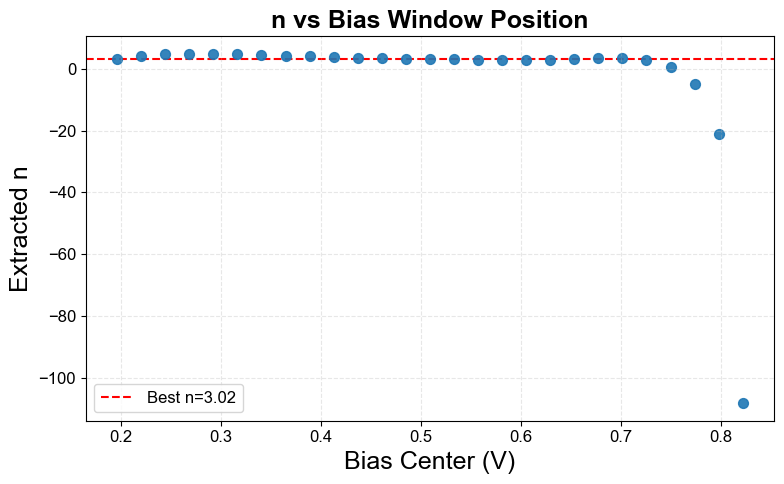

In [10]:
# 額外繪圖：n vs 窗口中心偏壓
fig, ax = plt.subplots(1, 1, figsize=(8, 5))

n_vs_V = []
for start_idx in range(0, len(bias_proc) - window_size + 1, step_size):
    end_idx = start_idx + window_size
    I_win = I_smooth[start_idx:end_idx]
    V_win = bias_proc[start_idx:end_idx]
    y_win = dV_dlnI[start_idx:end_idx]
    
    if not np.all(np.diff(I_win) > 0):
        continue
    # Cheung method I
    slope_a, intercept_a, r_value, _, _ = stats.linregress(I_win, y_win)
    n_ext = intercept_a / V_T
    V_center = (V_win[0] + V_win[-1]) / 2
    
    n_vs_V.append((V_center, n_ext))

if n_vs_V:
    V_centers, n_vals = zip(*n_vs_V)
    ax.scatter(V_centers, n_vals, s=50, alpha=0.9, zorder = 1)
    ax.axhline(y=best_result['n'], color='red', ls='--', label=f'Best n={best_result["n"]:.2f}', zorder = 0)
    ax.set_xlabel('Bias Center (V)')
    ax.set_ylabel('Extracted n')
    ax.set_title('n vs Bias Window Position')
    ax.legend(fontsize = 12)
    ax.grid(True, ls='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

In [11]:
# 並排繪圖：n vs V 和 R² vs V
if n_vs_V and r2_vs_V:
    V_centers_n, n_vals = zip(*n_vs_V)
    V_centers_r2, r2_vals = zip(*r2_vs_V)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
    
    # Panel 1: n vs V
    ax1.scatter(V_centers_n, n_vals, s=60, alpha=0.7, c='tab:blue', edgecolors='black', linewidth=0.2)
    if best_result:
        best_V_center = (best_result['V_range'][0] + best_result['V_range'][1]) / 2
        ax1.scatter([best_V_center], [best_result['n']], s=100, c='red', marker='*', edgecolors='black')
        ax1.axhline(y=best_result['n'], color='red', ls='--', alpha=0.7)
    ax1.set_xlabel('Bias Window Center (V)')
    ax1.set_ylabel('Extracted n')
    ax1.set_ylim(1, 6)
    ax1.set_title('n vs Bias Window', fontweight='bold')
    ax1.grid(True, ls='--', alpha=0.3)
    
    # Panel 2: R² vs V
    ax2.scatter(V_centers_r2, r2_vals, s=60, alpha=0.7, c='tab:orange', edgecolors='black', linewidth=0.2)
    if best_result:
        ax2.scatter([best_V_center], [best_result['r2']], s=100, c='red', marker='*', edgecolors='black')
        ax2.axhline(y=best_result['r2'], color='red', ls='--', alpha=0.7)
        ax2.axvline(x=best_V_center, color='red', ls=':', alpha=0.3)
    ax2.axhline(y=min_r_squared, color='gray', ls='-.', alpha=0.5)
    ax2.set_xlabel('Bias Window Center (V)')
    ax2.set_ylabel('R²')
    ax2.set_ylim(0.75, 1.05)
    ax2.set_title('R² vs Bias Window', fontweight='bold')
    ax2.grid(True, ls='--', alpha=0.3)
    
    plt.tight_layout()

    save_dir = Path("analysis_results/schottky_plots")
    save_dir.mkdir(parents=True, exist_ok=True)
    
    # 檔案名稱
    pixel_str = f"pixel_{x}_{y}"
    filename = f"n_vs_bias_R2_vs_bias.png"
    save_path = save_dir / filename
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    
    print(f"💾 圖表已儲存至：{save_path}")
    print(f"   檔案大小：{save_path.stat().st_size / 1024:.1f} KB")
    
    # 同時儲存為 PDF（矢量圖，適合論文）
    pdf_path = save_path.with_suffix('.pdf')
    plt.savefig(pdf_path, bbox_inches='tight')

    plt.show()
    
    # 解讀建議
    print("\n💡 解讀建議:")
    print("   • 理想情況：n 穩定 + R² 高 → 單一傳導機制")
    print("   • n 隨 V 變化 + R² 波動 → 機制轉變或界面態影響")
    print("   • 最佳窗口應落在 R² 峰值附近且 n 合理區間")

NameError: name 'r2_vs_V' is not defined